In [20]:

# ==============================================================================
# Cell 1: Environment Setup & Core Dependencies
# ==============================================================================

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: Data Splitting and Pipelines
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Scikit-Learn: Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

# Scikit-Learn: Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    RandomForestClassifier,
    VotingClassifier
)
from sklearn.svm import SVC

# Scikit-Learn: Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Suppress unnecessary warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Environment setup completed successfully!")
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)


Environment setup completed successfully!
NumPy Version: 2.1.3
Pandas Version: 2.3.3


In [21]:

# ==============================================================================
# Cell 2: Data Loading & Initial Cleaning
# ==============================================================================

# Dataset path in Kaggle
dataset_path = (
    "/kaggle/input/datasets/marymmohame/"
    "e-commerce-dataset/E Commerce Dataset.xlsx"
)

# Verify dataset path
if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"Dataset not found: {dataset_path}"
    )

print("Dataset found successfully!")

# Load Excel dataset
df_raw = pd.read_excel(
    dataset_path,
    sheet_name="E Comm"
)

print(
    f"Raw Dataset Shape: "
    f"{df_raw.shape[0]} rows, "
    f"{df_raw.shape[1]} columns"
)

display(df_raw.head())

# Drop non-predictive CustomerID
df = df_raw.drop(
    columns=["CustomerID"],
    errors="ignore"
).copy()

# Standardize categorical values
normalization_maps = {
    "PreferredLoginDevice": {
        "Phone": "Mobile Phone"
    },
    "PreferredPaymentMode": {
        "COD": "Cash on Delivery",
        "CC": "Credit Card"
    },
    "PreferedOrderCat": {
        "Mobile": "Mobile Phone"
    }
}

for column, mapping in normalization_maps.items():
    if column in df.columns:
        df[column] = df[column].replace(mapping)

# Validate target column
if "Churn" not in df.columns:
    raise ValueError("Target column 'Churn' not found!")

df["Churn"] = pd.to_numeric(
    df["Churn"],
    errors="coerce"
)

df = df.dropna(subset=["Churn"]).copy()
df = df[df["Churn"].isin([0, 1])].copy()
df["Churn"] = df["Churn"].astype(int)

# Duplicate inspection
print("\nDuplicate Rows:", df.duplicated().sum())

# Missing values inspection
print("\nMissing Values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nCleaned Dataset Shape:", df.shape)


Dataset found successfully!
Raw Dataset Shape: 5630 rows, 20 columns


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60



Duplicate Rows: 557

Missing Values:


,Missing Count
DaySinceLastOrder,307
OrderAmountHikeFromlastYear,265
Tenure,264
OrderCount,258
CouponUsed,256
HourSpendOnApp,255
WarehouseToHome,251
PreferredLoginDevice,0
Churn,0
PreferredPaymentMode,0



Cleaned Dataset Shape: (5630, 19)


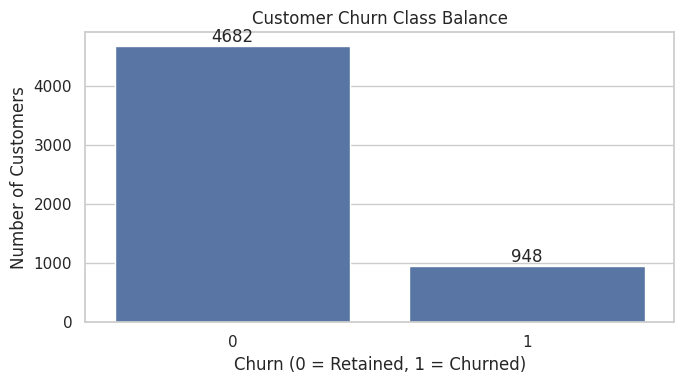

Churn Distribution:


,Percentage
Churn,
0,0.831616
1,0.168384


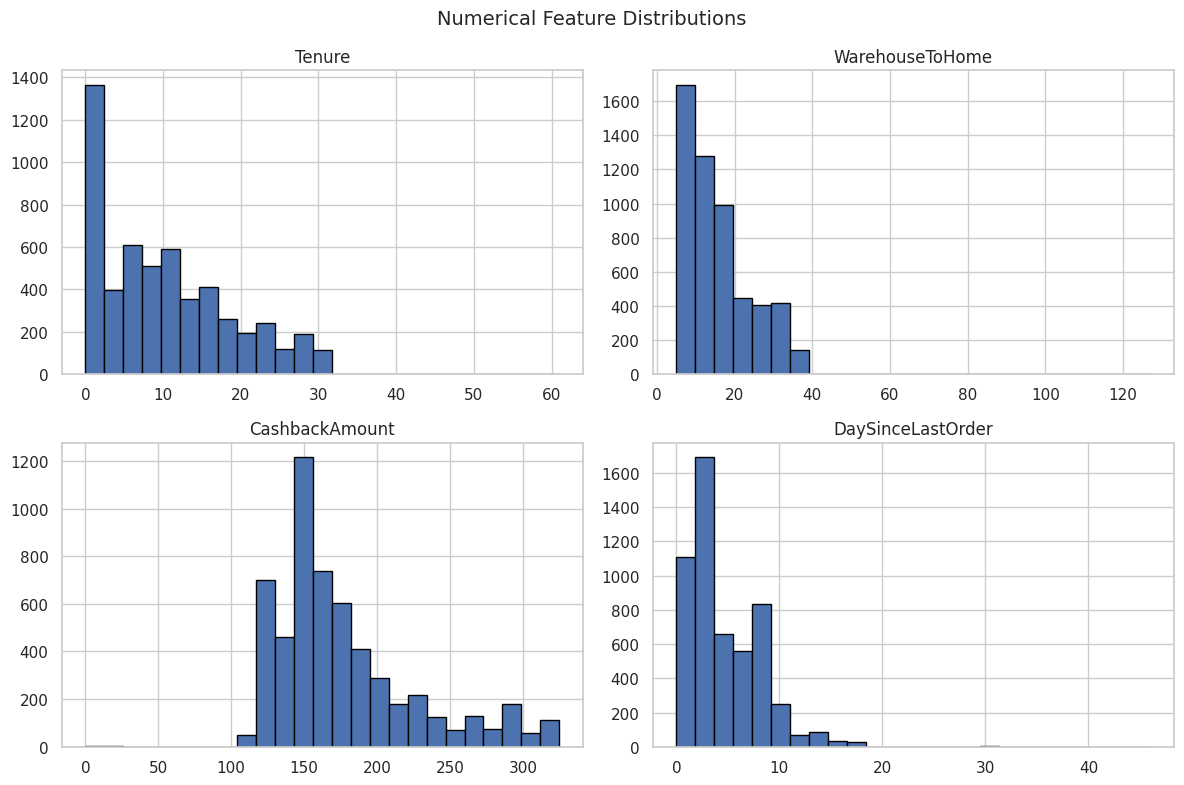

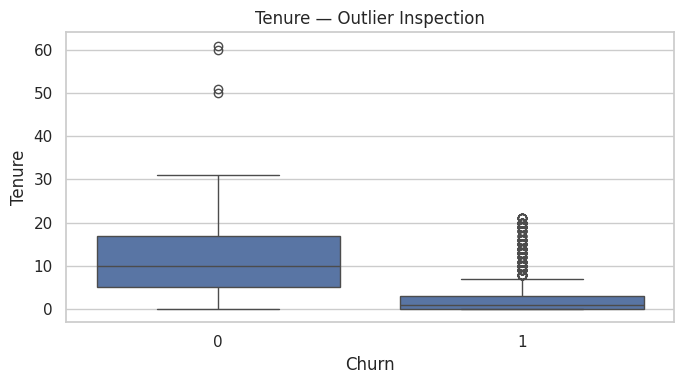

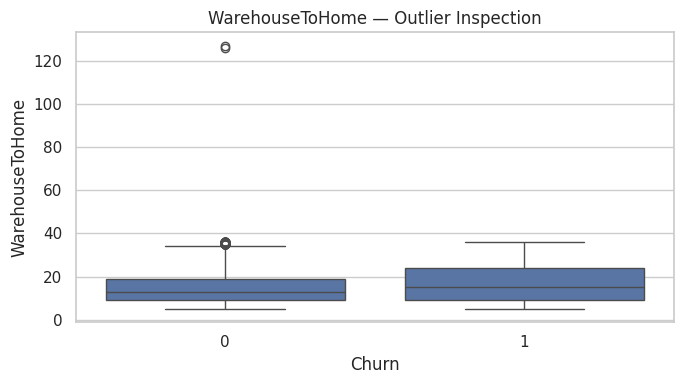

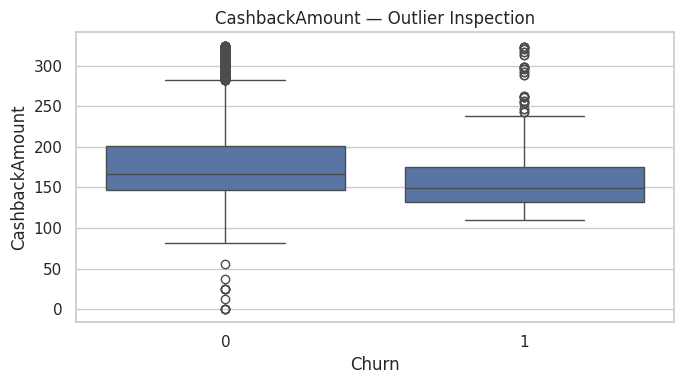

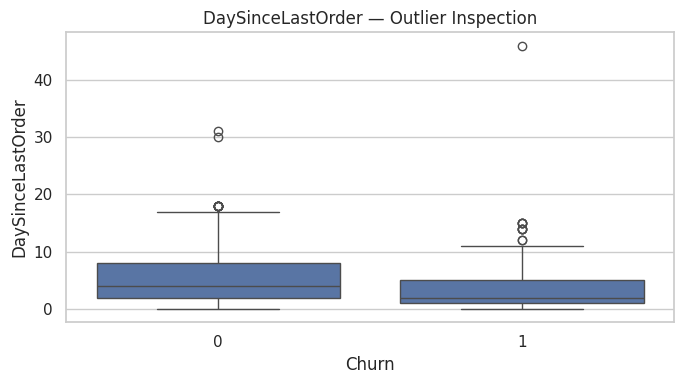

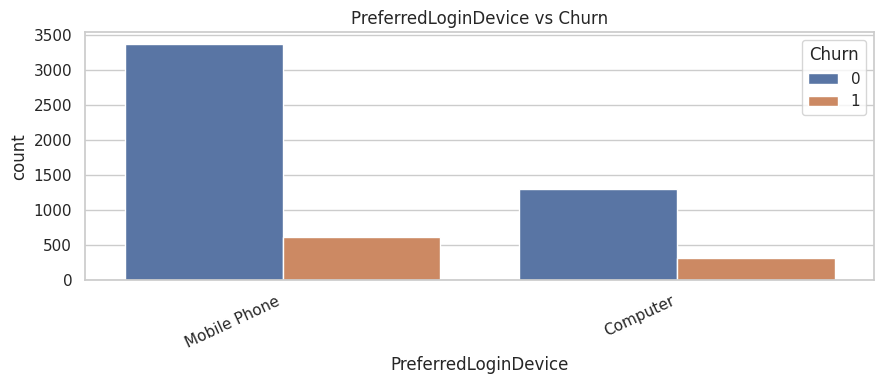

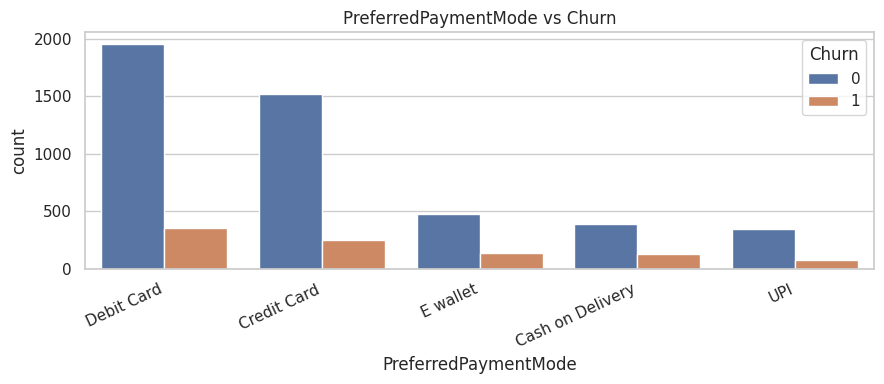

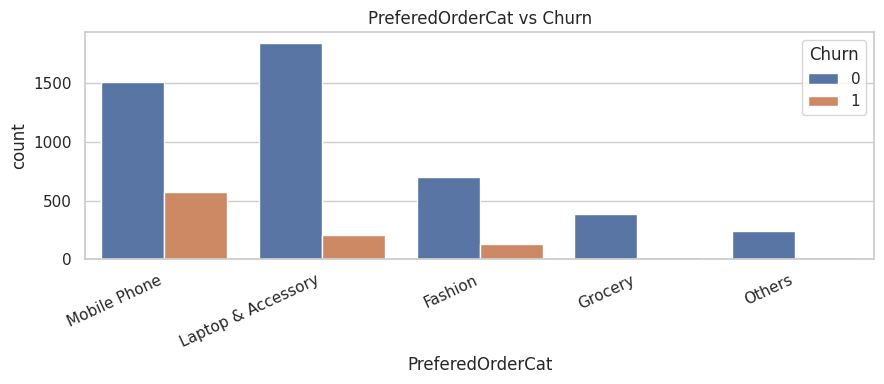

In [22]:

# ==============================================================================
# Cell 3: Exploratory Data Analysis
# ==============================================================================

# 1. Churn Class Balance

plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df,
    x="Churn"
)

ax.set_title("Customer Churn Class Balance")
ax.set_xlabel("Churn (0 = Retained, 1 = Churned)")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

print("Churn Distribution:")
display(
    df["Churn"]
    .value_counts(normalize=True)
    .rename("Percentage")
    .to_frame()
)

# 2. Numerical Features

numerical_features = [
    "Tenure",
    "WarehouseToHome",
    "CashbackAmount",
    "DaySinceLastOrder"
]

numerical_features = [
    col for col in numerical_features
    if col in df.columns
]

df[numerical_features].hist(
    figsize=(12, 8),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

# 3. Outlier Inspection using Boxplots

for column in numerical_features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Churn",
        y=column
    )

    plt.title(f"{column} — Outlier Inspection")
    plt.tight_layout()
    plt.show()

# 4. Categorical Features

categorical_features = [
    "PreferredLoginDevice",
    "PreferredPaymentMode",
    "PreferedOrderCat"
]

categorical_features = [
    col for col in categorical_features
    if col in df.columns
]

for column in categorical_features:

    plt.figure(figsize=(9, 4))

    sns.countplot(
        data=df,
        x=column,
        hue="Churn",
        order=df[column].value_counts().index
    )

    plt.title(f"{column} vs Churn")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


In [23]:

# ==============================================================================
# Cell 4: Reproducible Train/Test Split
# ==============================================================================

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
display(
    y_train.value_counts(normalize=True)
    .sort_index()
)

print("\nTesting Target Distribution:")
display(
    y_test.value_counts(normalize=True)
    .sort_index()
)


Training Features: (4504, 18)
Testing Features: (1126, 18)

Training Target Distribution:


Churn
0    0.831705
1    0.168295
Name: proportion, dtype: float64


Testing Target Distribution:


Churn
0    0.831261
1    0.168739
Name: proportion, dtype: float64

In [24]:

# ==============================================================================
# Cell 5: Identify Numerical and Categorical Columns
# ==============================================================================

num_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

cat_cols = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Columns:")
print(num_cols)

print("\nCategorical Columns:")
print(cat_cols)

print("\nNumber of Numerical Features:", len(num_cols))
print("Number of Categorical Features:", len(cat_cols))


Numerical Columns:
['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

Categorical Columns:
['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']

Number of Numerical Features: 13
Number of Categorical Features: 5


In [25]:

# ==============================================================================
# Cell 6: Inspect SimpleImputer Statistics
# ==============================================================================

numeric_imputer = SimpleImputer(
    strategy="median"
)

numeric_imputer.fit(
    X_train[num_cols]
)

print("Learned Median Values:")

for column, median in zip(
    num_cols,
    numeric_imputer.statistics_
):
    print(f"{column}: {median}")


Learned Median Values:
Tenure: 9.0
CityTier: 1.0
WarehouseToHome: 14.0
HourSpendOnApp: 3.0
NumberOfDeviceRegistered: 4.0
SatisfactionScore: 3.0
NumberOfAddress: 3.0
Complain: 0.0
OrderAmountHikeFromlastYear: 15.0
CouponUsed: 1.0
OrderCount: 2.0
DaySinceLastOrder: 3.0
CashbackAmount: 163.76


In [26]:

# ==============================================================================
# Cell 8: Numerical and Categorical Pipelines
# ==============================================================================

# Numerical Pipeline

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            MinMaxScaler()
        )
    ]
)

# Categorical Pipeline

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

print("Numerical and Categorical Pipelines Created!")


Numerical and Categorical Pipelines Created!


In [27]:

# ==============================================================================
# Cell 9: ColumnTransformer and Master Pipeline
# ==============================================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            num_cols
        ),
        (
            "cat",
            categorical_pipeline,
            cat_cols
        )
    ]
)

master_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

print("ColumnTransformer and Master Pipeline Created!")


ColumnTransformer and Master Pipeline Created!


In [28]:

# ==============================================================================
# Cell 10: Train and Evaluate Master Pipeline
# ==============================================================================

master_pipeline.fit(
    X_train,
    y_train
)

master_predictions = master_pipeline.predict(
    X_test
)

master_probabilities = master_pipeline.predict_proba(
    X_test
)[:, 1]

print("Master Pipeline Results")

print(
    "Accuracy:",
    accuracy_score(y_test, master_predictions)
)

print(
    "Precision:",
    precision_score(y_test, master_predictions, zero_division=0)
)

print(
    "Recall:",
    recall_score(y_test, master_predictions, zero_division=0)
)

print(
    "F1-Score:",
    f1_score(y_test, master_predictions, zero_division=0)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, master_probabilities)
)


Master Pipeline Results
Accuracy: 0.8854351687388987
Precision: 0.7747747747747747
Recall: 0.45263157894736844
F1-Score: 0.5714285714285714
ROC-AUC: 0.881798245614035


In [29]:

# ==============================================================================
# Cell 11: Underfitting vs. Overfitting
# ==============================================================================

# High-Bias Model: Decision Stump

stump_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=1,
                random_state=42
            )
        )
    ]
)

# Complex Model: Unrestricted Decision Tree

complex_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=None,
                min_samples_leaf=1,
                random_state=42
            )
        )
    ]
)

stump_pipeline.fit(X_train, y_train)
complex_tree_pipeline.fit(X_train, y_train)

complexity_results = []

for name, model in [
    ("Decision Tree (Depth=1)", stump_pipeline),
    ("Decision Tree (Unrestricted)", complex_tree_pipeline)
]:

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    complexity_results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train,
            train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test,
            test_predictions
        ),
        "Train F1": f1_score(
            y_train,
            train_predictions,
            zero_division=0
        ),
        "Test F1": f1_score(
            y_test,
            test_predictions,
            zero_division=0
        )
    })

complexity_df = pd.DataFrame(complexity_results)

display(complexity_df)


,Model,Train Accuracy,Test Accuracy,Train F1,Test F1
0,Decision Tree (Depth=1),0.838366,0.843694,0.579677,0.574879
1,Decision Tree (Unrestricted),1.000000,0.975133,1.000000,0.926316


In [30]:

# ==============================================================================
# Cell 12: L1, L2 and Elastic Net Regularization
# ==============================================================================

regularization_configs = [
    {
        "Model": "Logistic Regression L2",
        "penalty": "l2",
        "l1_ratio": None
    },
    {
        "Model": "Logistic Regression L1",
        "penalty": "l1",
        "l1_ratio": None
    },
    {
        "Model": "Logistic Regression Elastic Net",
        "penalty": "elasticnet",
        "l1_ratio": 0.5
    }
]

regularization_results = []
regularized_models = {}

for config in regularization_configs:

    model_name = config["Model"]

    classifier = LogisticRegression(
        solver="saga",
        penalty=config["penalty"],
        l1_ratio=config["l1_ratio"],
        max_iter=2000,
        random_state=42
    )

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    regularization_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })

    regularized_models[model_name] = pipeline

regularization_df = pd.DataFrame(
    regularization_results
).sort_values(
    by="F1-Score",
    ascending=False
)

display(regularization_df)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Logistic Regression L1,0.892540,0.776000,0.510526,0.615873,0.885959
2,Logistic Regression Elastic Net,0.888988,0.787611,0.468421,0.587459,0.884014
0,Logistic Regression L2,0.885435,0.774775,0.452632,0.571429,0.881838


In [31]:

# ==============================================================================
# Cell 13: Bagging vs. Pasting
# ==============================================================================

# Bagging: Sampling with replacement

bagging_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "ensemble",
            BaggingClassifier(
                estimator=DecisionTreeClassifier(
                    random_state=42
                ),
                n_estimators=100,
                max_samples=1.0,
                bootstrap=True,
                oob_score=True,
                n_jobs=-1,
                random_state=42
            )
        )
    ]
)

# Pasting: Sampling without replacement

pasting_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "ensemble",
            BaggingClassifier(
                estimator=DecisionTreeClassifier(
                    random_state=42
                ),
                n_estimators=100,
                max_samples=1.0,
                bootstrap=False,
                n_jobs=-1,
                random_state=42
            )
        )
    ]
)

bagging_pipeline.fit(X_train, y_train)
pasting_pipeline.fit(X_train, y_train)

bagging_predictions = bagging_pipeline.predict(X_test)
pasting_predictions = pasting_pipeline.predict(X_test)

bagging_test_accuracy = accuracy_score(
    y_test,
    bagging_predictions
)

pasting_test_accuracy = accuracy_score(
    y_test,
    pasting_predictions
)

oob_score = bagging_pipeline.named_steps[
    "ensemble"
].oob_score_

bag_pasting_results = pd.DataFrame([
    {
        "Model": "Bagging",
        "Test Accuracy": bagging_test_accuracy,
        "Test F1": f1_score(
            y_test, bagging_predictions, zero_division=0
        )
    },
    {
        "Model": "Pasting",
        "Test Accuracy": pasting_test_accuracy,
        "Test F1": f1_score(
            y_test, pasting_predictions, zero_division=0
        )
    }
])

display(bag_pasting_results)

print("Bagging OOB Score:", oob_score)
print("Bagging Test Accuracy:", bagging_test_accuracy)

print(
    "Absolute Difference:",
    abs(oob_score - bagging_test_accuracy)
)


,Model,Test Accuracy,Test F1
0,Bagging,0.986679,0.960212
1,Pasting,0.976909,0.931937


Bagging OOB Score: 0.9693605683836589
Bagging Test Accuracy: 0.9866785079928952
Absolute Difference: 0.017317939609236332


In [32]:

# ==============================================================================
# Cell 14: AdaBoost Classifier
# ==============================================================================

adaboost_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "ensemble",
            AdaBoostClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=1,
                    random_state=42
                ),
                n_estimators=100,
                learning_rate=0.5,
                random_state=42
            )
        )
    ]
)

adaboost_pipeline.fit(X_train, y_train)

ada_predictions = adaboost_pipeline.predict(X_test)

ada_probabilities = adaboost_pipeline.predict_proba(X_test)[:, 1]

adaboost_results = pd.DataFrame([{
    "Model": "AdaBoost",
    "Accuracy": accuracy_score(y_test, ada_predictions),
    "Precision": precision_score(
        y_test, ada_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, ada_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, ada_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, ada_probabilities
    )
}])

display(adaboost_results)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,AdaBoost,0.880107,0.76699,0.415789,0.539249,0.896733


In [33]:

# ==============================================================================
# Cell 15: Hard Voting vs. Soft Voting
# ==============================================================================

voting_estimators = [
    (
        "lr",
        Pipeline(steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(
                    max_iter=2000,
                    random_state=42
                )
            )
        ])
    ),
    (
        "rf",
        Pipeline(steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=200,
                    n_jobs=-1,
                    random_state=42
                )
            )
        ])
    ),
    (
        "svc",
        Pipeline(steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                SVC(
                    probability=True,
                    random_state=42
                )
            )
        ])
    )
]

# Hard Voting
hard_voting = VotingClassifier(
    estimators=voting_estimators,
    voting="hard",
    n_jobs=-1
)

# Soft Voting
soft_voting = VotingClassifier(
    estimators=voting_estimators,
    voting="soft",
    n_jobs=-1
)

hard_voting.fit(X_train, y_train)
soft_voting.fit(X_train, y_train)

hard_predictions = hard_voting.predict(X_test)
soft_predictions = soft_voting.predict(X_test)

soft_probabilities = soft_voting.predict_proba(X_test)[:, 1]

voting_results = pd.DataFrame([
    {
        "Model": "Hard Voting",
        "Accuracy": accuracy_score(y_test, hard_predictions),
        "Precision": precision_score(
            y_test, hard_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, hard_predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, hard_predictions, zero_division=0
        ),
        "ROC-AUC": np.nan
    },
    {
        "Model": "Soft Voting",
        "Accuracy": accuracy_score(y_test, soft_predictions),
        "Precision": precision_score(
            y_test, soft_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, soft_predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, soft_predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, soft_probabilities
        )
    }
])

display(voting_results)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Hard Voting,0.912966,0.910714,0.536842,0.675497,NaN
1,Soft Voting,0.921847,0.898438,0.605263,0.723270,0.977525


In [34]:

# ==============================================================================
# Cell 16: Comprehensive Model Comparison
# ==============================================================================

def evaluate_classifier(name, model, X_eval, y_eval):

    predictions = model.predict(X_eval)

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_eval, predictions, zero_division=0
        )
    }

    if hasattr(model, "predict_proba"):

        probabilities = model.predict_proba(X_eval)[:, 1]

        results["ROC-AUC"] = roc_auc_score(
            y_eval,
            probabilities
        )

    else:
        results["ROC-AUC"] = np.nan

    return results


all_results = [
    evaluate_classifier(
        "Master Logistic Regression",
        master_pipeline,
        X_test,
        y_test
    ),

    evaluate_classifier(
        "Decision Tree (Depth=1)",
        stump_pipeline,
        X_test,
        y_test
    ),

    evaluate_classifier(
        "Decision Tree (Unrestricted)",
        complex_tree_pipeline,
        X_test,
        y_test
    ),

    evaluate_classifier(
        "Bagging",
        bagging_pipeline,
        X_test,
        y_test
    ),

    evaluate_classifier(
        "Pasting",
        pasting_pipeline,
        X_test,
        y_test
    ),

    evaluate_classifier(
        "AdaBoost",
        adaboost_pipeline,
        X_test,
        y_test
    ),

    evaluate_classifier(
        "Hard Voting",
        hard_voting,
        X_test,
        y_test
    ),

    evaluate_classifier(
        "Soft Voting",
        soft_voting,
        X_test,
        y_test
    )
]

# Add regularized Logistic Regression models

for model_name, model in regularized_models.items():

    all_results.append(
        evaluate_classifier(
            model_name,
            model,
            X_test,
            y_test
        )
    )

leaderboard = pd.DataFrame(
    all_results
).sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(
    leaderboard.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Bagging,0.9867,0.9679,0.9526,0.9602,0.9979
1,Pasting,0.9769,0.9271,0.9368,0.9319,0.9762
2,Decision Tree (Unrestricted),0.9751,0.9263,0.9263,0.9263,0.9557
3,Soft Voting,0.9218,0.8984,0.6053,0.7233,0.9775
4,Hard Voting,0.9130,0.9107,0.5368,0.6755,nan
5,Logistic Regression L1,0.8925,0.7760,0.5105,0.6159,0.8860
6,Logistic Regression Elastic Net,0.8890,0.7876,0.4684,0.5875,0.8840
7,Decision Tree (Depth=1),0.8437,0.5312,0.6263,0.5749,0.7571
8,Master Logistic Regression,0.8854,0.7748,0.4526,0.5714,0.8818
9,Logistic Regression L2,0.8854,0.7748,0.4526,0.5714,0.8818


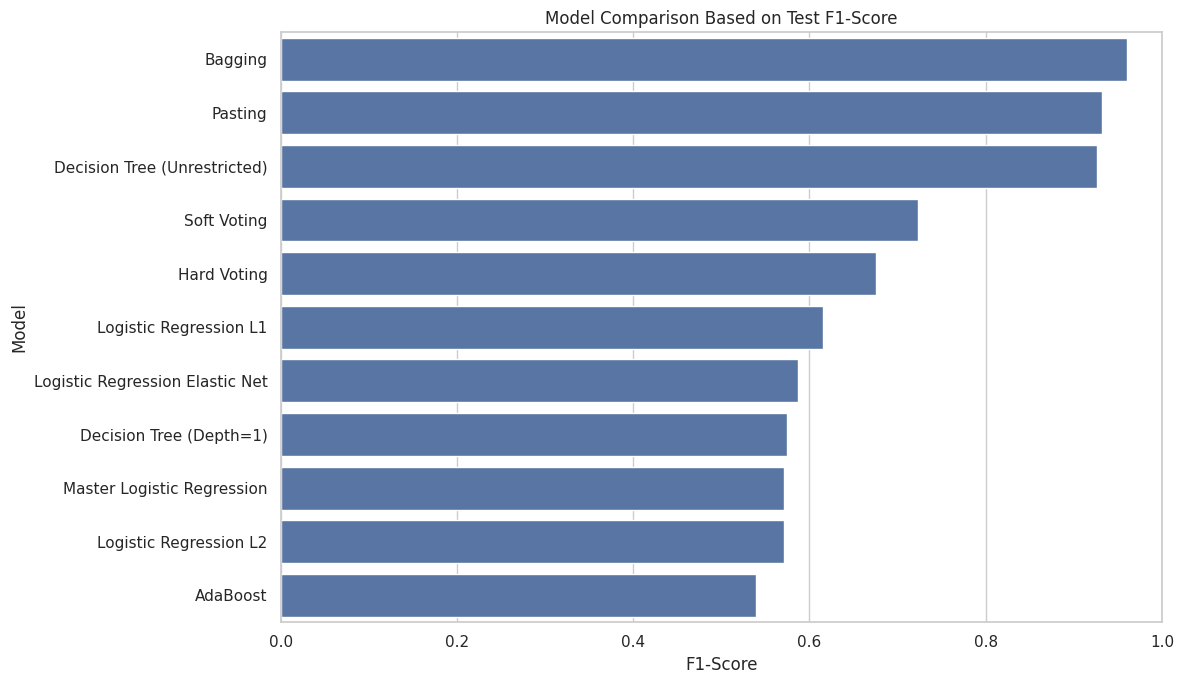

In [35]:

# ==============================================================================
# Cell 17: Model Comparison Visualization
# ==============================================================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=leaderboard,
    x="F1-Score",
    y="Model"
)

plt.title("Model Comparison Based on Test F1-Score")
plt.xlabel("F1-Score")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()


Best Model: Bagging

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       936
           1       0.97      0.95      0.96       190

    accuracy                           0.99      1126
   macro avg       0.98      0.97      0.98      1126
weighted avg       0.99      0.99      0.99      1126



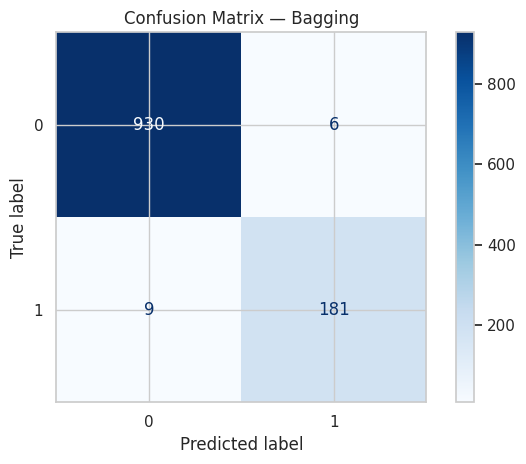

In [36]:

# ==============================================================================
# Cell 18: Best Model Evaluation
# ==============================================================================

model_lookup = {
    "Master Logistic Regression": master_pipeline,
    "Decision Tree (Depth=1)": stump_pipeline,
    "Decision Tree (Unrestricted)": complex_tree_pipeline,
    "Bagging": bagging_pipeline,
    "Pasting": pasting_pipeline,
    "AdaBoost": adaboost_pipeline,
    "Hard Voting": hard_voting,
    "Soft Voting": soft_voting,
    **regularized_models
}

best_model_name = leaderboard.loc[0, "Model"]

best_model = model_lookup[best_model_name]

best_predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


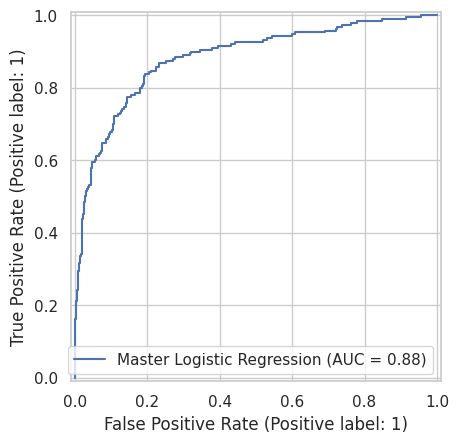

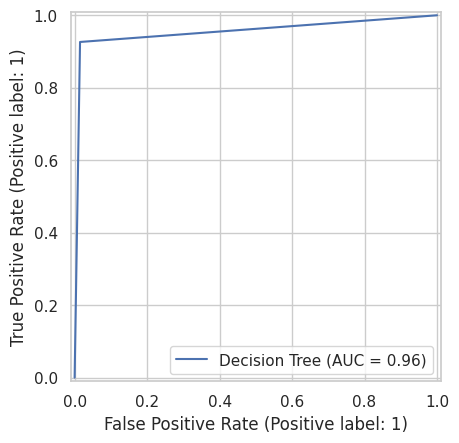

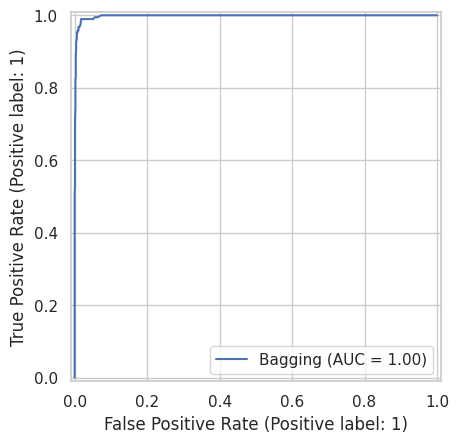

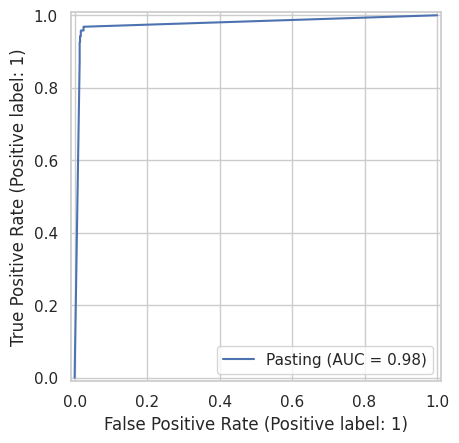

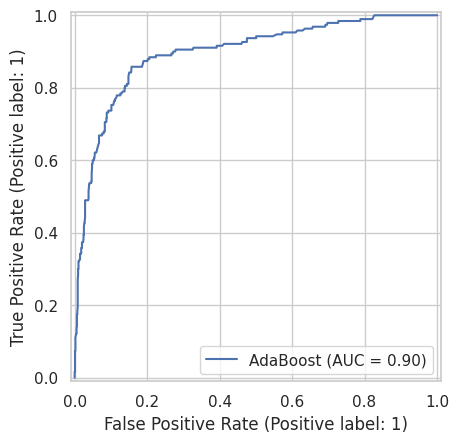

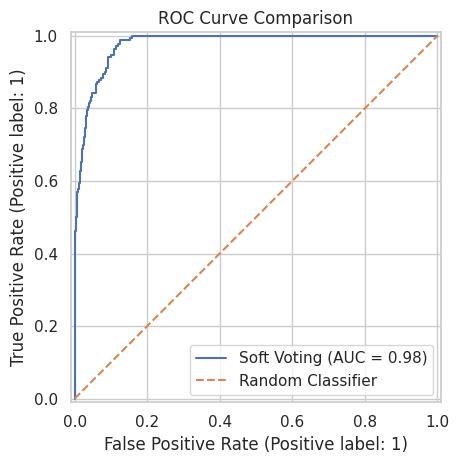

In [37]:

# ==============================================================================
# Cell 19: ROC Curve Comparison
# ==============================================================================

roc_models = {
    "Master Logistic Regression": master_pipeline,
    "Decision Tree": complex_tree_pipeline,
    "Bagging": bagging_pipeline,
    "Pasting": pasting_pipeline,
    "AdaBoost": adaboost_pipeline,
    "Soft Voting": soft_voting
}

for model_name, model in roc_models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()
